In [1]:
import random
import statistics
import matplotlib.pyplot as plt

from src.prey_predator_sim.population import Population
from src.prey_predator_sim.species import Prey, Predator

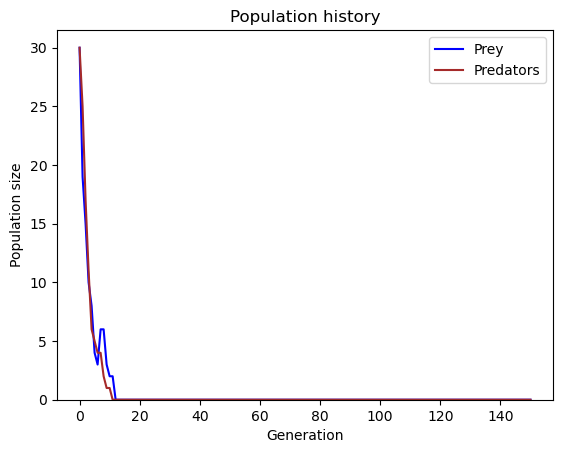

In [2]:
random.seed(2026)

population = Population(
    population_data={
        Prey: 30,
        Predator: 30
    },
    species_parameters={
        Prey: {
            "p_death": 0.5,
            "p_reproduce": 0.5,
            "p_hunt": 0.5
        },
        Predator: {
            "p_death": 0.5,
            "p_reproduce": 0.5
        }
    }
)

for _ in range(150):
    population.natural_selection()

population.plot_history()

In [3]:
def run_simulation(
    seed: int,
    n_prey: int,
    n_predator: int,
    prey_p_death: float,
    prey_p_reproduce: float,
    prey_p_hunt: float,
    predator_p_death: float,
    predator_p_reproduce: float,
    steps: int = 150,
    plot: bool = False
):
    random.seed(seed)

    population = Population(
        population_data={
            Prey: n_prey,
            Predator: n_predator
        },
        species_parameters={
            Prey: {
                "p_death": prey_p_death,
                "p_reproduce": prey_p_reproduce,
                "p_hunt": prey_p_hunt
            },
            Predator: {
                "p_death": predator_p_death,
                "p_reproduce": predator_p_reproduce
            }
        }
    )

    for _ in range(steps):
        population.natural_selection()

    if plot:
        population.plot_history()

    return population.history


history_1 = run_simulation(
    seed=2026,
    n_prey=30,
    n_predator=30,
    prey_p_death=0.5,
    prey_p_reproduce=0.5,
    prey_p_hunt=0.5,
    predator_p_death=0.5,
    predator_p_reproduce=0.5
)

history_2 = run_simulation(
    seed=2026,
    n_prey=30,
    n_predator=30,
    prey_p_death=0.5,
    prey_p_reproduce=0.5,
    prey_p_hunt=0.5,
    predator_p_death=0.5,
    predator_p_reproduce=0.5
)

print("Identyczne???", history_1 == history_2)

Identyczne??? True


In [4]:
def run_experiment(
    repetitions: int,
    n_prey: int,
    n_predator: int,
    prey_p_death: float,
    prey_p_reproduce: float,
    prey_p_hunt: float,
    predator_p_death: float,
    predator_p_reproduce: float,
    steps: int = 150,
    seed_start: int = 0,
    plot: bool = False
):
    results = []

    for i in range(repetitions):

        history = run_simulation(
            seed=seed_start + i,
            n_prey=n_prey,
            n_predator=n_predator,
            prey_p_death=prey_p_death,
            prey_p_reproduce=prey_p_reproduce,
            prey_p_hunt=prey_p_hunt,
            predator_p_death=predator_p_death,
            predator_p_reproduce=predator_p_reproduce,
            steps=steps,
            plot=plot
        )

        results.append(history[-1])

    prey_final = [result[Prey] for result in results]
    predator_final = [result[Predator] for result in results]

    total_final = [
        prey_final[i] + predator_final[i]
        for i in range(repetitions)
    ]

    print(f"\nResults after {repetitions} simulations ({steps} steps)")

    print(
        f"Prey extinction: "
        f"{sum(x == 0 for x in prey_final) / repetitions * 100:.2f}%"
    )

    print(
        f"Predator extinction: "
        f"{sum(x == 0 for x in predator_final) / repetitions * 100:.2f}%"
    )

    print(
        f"Final population mean: "
        f"{statistics.mean(total_final):.2f}"
    )

    print(
        f"Final population standard deviation: "
        f"{statistics.stdev(total_final):.2f}"
    )

    return results

In [5]:
results = run_experiment(
    repetitions=10,
    n_prey=30,
    n_predator=30,
    prey_p_death=0.05,
    prey_p_reproduce=0.5,
    prey_p_hunt=0.5,
    predator_p_death=0.05,
    predator_p_reproduce=0.5,
    steps=150,
    seed_start=2026,
    plot=False
)


Results after 10 simulations (150 steps)
Prey extinction: 100.00%
Predator extinction: 40.00%
Final population mean: 10.60
Final population standard deviation: 21.46


In [6]:
parameters = {
    "prey_p_death": [0.3, 0.5, 0.7],
    "predator_p_death": [0.3, 0.5, 0.7]
}

sensitivity_results = []

for parameter, values in parameters.items():

    for value in values:

        parameters_values = {
            "prey_p_death": 0.5,
            "predator_p_death": 0.5
        }

        parameters_values[parameter] = value

        results = run_experiment(
            repetitions=10,
            n_prey=30,
            n_predator=30,
            prey_p_death=parameters_values["prey_p_death"],
            prey_p_reproduce=0.5,
            prey_p_hunt=0.5,
            predator_p_death=parameters_values["predator_p_death"],
            predator_p_reproduce=0.5,
            steps=50,
            seed_start=2026,
            plot=False
        )

        prey_final = [result[Prey] for result in results]
        predator_final = [result[Predator] for result in results]

        total_final = [
            prey_final[i] + predator_final[i]
            for i in range(10)
        ]

        sensitivity_results.append({
            "Parameter": parameter,
            "Value": value,
            "Prey extinction (%)":
                sum(x == 0 for x in prey_final) / 10 * 100,
            "Predator extinction (%)":
                sum(x == 0 for x in predator_final) / 10 * 100,
            "Mean": statistics.mean(total_final),
            "Standard deviation": statistics.stdev(total_final)
        })

print("\nSENSITIVITY ANALYSIS")

for result in sensitivity_results:
    print(result)


Results after 10 simulations (50 steps)
Prey extinction: 10.00%
Predator extinction: 100.00%
Final population mean: 12665.10
Final population standard deviation: 14256.12

Results after 10 simulations (50 steps)
Prey extinction: 100.00%
Predator extinction: 100.00%
Final population mean: 0.00
Final population standard deviation: 0.00

Results after 10 simulations (50 steps)
Prey extinction: 100.00%
Predator extinction: 100.00%
Final population mean: 0.00
Final population standard deviation: 0.00

Results after 10 simulations (50 steps)
Prey extinction: 100.00%
Predator extinction: 100.00%
Final population mean: 0.00
Final population standard deviation: 0.00

Results after 10 simulations (50 steps)
Prey extinction: 100.00%
Predator extinction: 100.00%
Final population mean: 0.00
Final population standard deviation: 0.00

Results after 10 simulations (50 steps)
Prey extinction: 90.00%
Predator extinction: 100.00%
Final population mean: 1.70
Final population standard deviation: 5.38

SEN

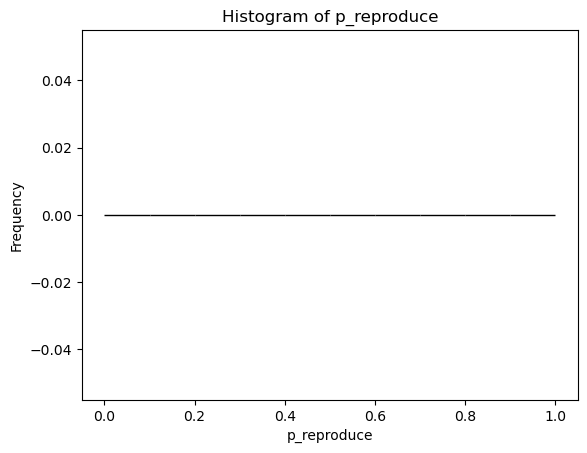

In [7]:
random.seed(2026)

histogram_population = Population(
    population_data={
        Prey: 30,
        Predator: 30
    },
    species_parameters={
        Prey: {
            "p_death": 0.6,
            "p_reproduce": 0.55,
            "p_hunt": 0.5
        },
        Predator: {
            "p_death": 0.5,
            "p_reproduce": 0.5
        }
    }
)

for _ in range(140):
    histogram_population.natural_selection()

histogram_population.plot_histogram("p_reproduce")